[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L5/BA_L5_gegenbauer/BA_L5_gegenbauer.ipynb)

# BA_L5_gegenbauer: Gegenbauer Scores of a Liquidity Curve

*Quantlet of Lecture 5, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Orthonormal Gegenbauer polynomials (alpha = 0.3) and the weighted least-squares decomposition, up to degree 7, of a stylised peg-centred log-liquidity curve of a Uniswap V3 pool and of its mirror image. Stylised example, no market data.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

Setup: chart style and colours of the slides, and a `save()` helper that puts one legend below the figure.

In [4]:
import matplotlib
import matplotlib.dates as mdates
from scipy import stats

# the slide charts use matplotlib's default sizes with 10-point text and an 8-point legend
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 'medium', 'axes.titlesize': 'large', 'axes.linewidth': 0.8,
                     'lines.linewidth': 1.5, 'legend.fontsize': 8})
COL = {'USDT': GREEN, 'USDC': BLUE, 'DAI': GOLD}


def save(fig, name, bottom, ncol=3):
    """One legend for all panels below the plot (as on the slide), then save to OUT_PATH and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)

## What the chart shows

On Uniswap V3, liquidity providers choose a price range; prices live on ticks $p_k = 1.0001^k$ (one tick is 1 basis point) and the active liquidity at each tick forms a curve that changes every hour.
The ticks around the peg are mapped to $x \in [-1, 1]$ (peg at $x = 0$), the log-liquidity is $\ell(x) = \log\{L(x) + 1\}$, and it is expanded in Gegenbauer polynomials, orthonormal under the weight $w_\alpha$:

$$ \ell(x) \approx \sum_{k=0}^{K} \beta_{k}\, \phi_k^{(\alpha)}(x), \qquad w_\alpha(x) = (1 - x^2)^{\alpha - 1/2}, \qquad \beta_{k} = \int_{-1}^{1} \ell(x)\,\phi_k^{(\alpha)}(x)\,w_\alpha(x)\,dx . $$

$k = 0$ measures the level of liquidity, $k = 1$ the left-right asymmetry, $k = 2$ the concentration at the peg; odd $k$ are asymmetric, even $k$ symmetric.
The energies are $E^{odd} = \sum_{k \text{ odd}} \beta_{k}^2$ and $E^{even} = \sum_{k \geq 2 \text{ even}} \beta_{k}^2$.

Left: the first five basis functions for $\alpha = 0.3$. Middle: a stylised curve (deep band at the peg, extra depth below parity, a cliff above $x = 0.5$) and its reconstruction with $K = 7$, fitted by weighted least squares on 101 ticks. Right: the coefficients of the curve and of its mirror image.

In [5]:
from scipy import special

alpha = 0.3


def phi(k, x, a=alpha):
    """Orthonormal Gegenbauer polynomial of degree k."""
    h = np.pi * 2 ** (1 - 2 * a) * special.gamma(k + 2 * a) / (special.factorial(k) * (k + a) * special.gamma(a) ** 2)
    return special.eval_gegenbauer(k, a, x) / np.sqrt(h)


xg = -1 + (2 * np.arange(101) + 1) / 101                    # 101 ticks, peg at x = 0
wg = (1 - xg ** 2) ** (alpha - 0.5)
L = 4e7 * np.exp(-(xg / 0.06) ** 2) + 6e6 * np.exp(-((xg + 0.25) / 0.12) ** 2) + 4e5 * (xg < 0.5) + 5e3
Ls = 4e7 * np.exp(-(xg / 0.06) ** 2) + 6e6 * np.exp(-((xg - 0.25) / 0.12) ** 2) + 4e5 * (xg > -0.5) + 5e3     # mirror image
ell = np.log(L + 1)
K = 7
Phi = np.column_stack([phi(k, xg) for k in range(K + 1)])
Wm = np.diag(wg)
beta = np.linalg.solve(Phi.T @ Wm @ Phi, Phi.T @ Wm @ ell)
beta_m = np.linalg.solve(Phi.T @ Wm @ Phi, Phi.T @ Wm @ np.log(Ls + 1))
fit = Phi @ beta

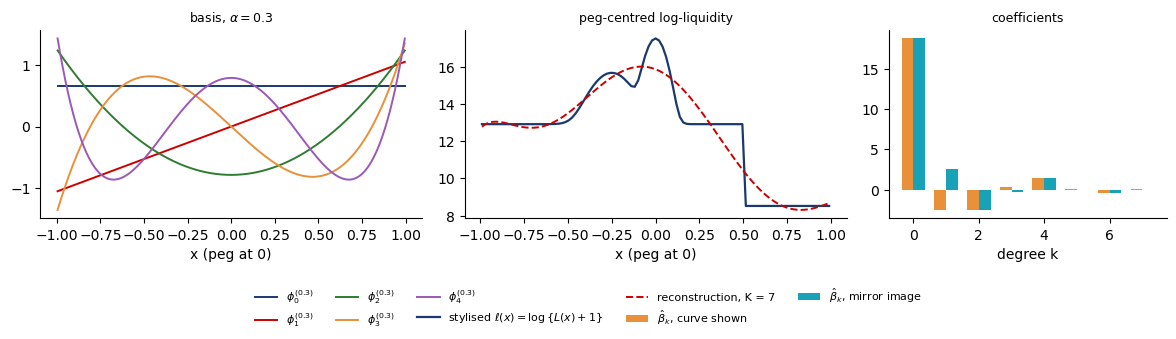

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4), gridspec_kw={'width_ratios': [1.1, 1.1, 0.8]})
xx = np.linspace(-0.995, 0.995, 400)
for k, col in zip(range(5), [BLUE, RED, GREEN, BTC, ETH]):
    ax[0].plot(xx, phi(k, xx), color=col, lw=1.4, label=f'$\\phi_{k}^{{(0.3)}}$')
ax[0].set_xlabel('x (peg at 0)'); ax[0].set_title(r'basis, $\alpha = 0.3$', fontsize=9)
ax[1].plot(xg, ell, color=BLUE, lw=1.6, label=r'stylised $\ell(x) = \log\{L(x)+1\}$')
ax[1].plot(xg, fit, color=RED, ls='--', lw=1.4, label='reconstruction, K = 7')
ax[1].set_xlabel('x (peg at 0)'); ax[1].set_title('peg-centred log-liquidity', fontsize=9)
ax[2].bar(np.arange(K + 1) - 0.18, beta, width=0.36, color=BTC, label=r'$\hat\beta_k$, curve shown')
ax[2].bar(np.arange(K + 1) + 0.18, beta_m, width=0.36, color=TEAL, label=r'$\hat\beta_k$, mirror image')
ax[2].set_xlabel('degree k'); ax[2].set_title('coefficients', fontsize=9)
save(fig, 'ba_l5_gegenbauer', 0.17, ncol=5)

## Key numbers

In [7]:
print(f'odd energy E_odd = {(beta[1::2] ** 2).sum():.2f}; even energy E_even = {(beta[2::2] ** 2).sum():.2f}')
pd.DataFrame({'beta_k, curve shown': beta, 'beta_k, mirror image': beta_m}, index=pd.Index(range(K + 1), name='degree k')).round(2)

odd energy E_odd = 6.48; even energy E_even = 8.55


,"beta_k, curve shown","beta_k, mirror image"
degree k,,
0,18.78,18.78
1,-2.52,2.52
2,-2.50,-2.50
3,0.32,-0.32
4,1.45,1.45
5,0.08,-0.08
6,-0.43,-0.43
7,0.07,-0.07


**How to read it:** the mirror image has the same even coefficients and odd coefficients with the opposite sign: the odd scores carry the direction of fragility.
A fixed basis keeps the scores comparable over time, unlike a rolling functional principal component analysis (FPCA).